# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Domingo, Judiele Fatima P.
- _Student No._: 2023-05167
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="Minimization.png" alt="Local Extrema graphs" width=55%> 

**Figure 1:** Local minima and maxima of $\phi(x)$ and $f(x)$ and their derivatives.

Fig. 1 shows the local minima and maxima of the functions $\phi(x), f(x), \phi'(x), f'(x)$. Each subplot marks the local minima with triangles and the local maxima with circles. The coordinates are annotated for each extrema. 


### Report discussion
The golden section search method becomes less efficient if a number other than the golden ratio is used. The use of the golden ratio allows reusing of previous function evaluations. If another number is used, the search method takes longer and performs like a dichotomous search which doubles the operation cost per iteration.

### Other comments
- N/A

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [2]:
#defining original functions

def phi(x):
    return x**4 - 9*x**3 + 25*x**2 - 24*x + 4
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 +x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x +4*np.exp(x) - 8

#defining derivatives 
def phi_prime(x):
    return 4*x**3 - 27*x**2 + 50*x - 24
def f_prime(x):
    return -5*x**4 + 16*x**3 - 12*x**2 + 2*x*np.exp(x) +x**2*np.exp(x) - 4*x**2 -4*np.exp(x) -4*x*np.exp(x) +8 +4*np.exp(x)


In [3]:
#defining golden_section funtion taken from gezerlis
def golden_section(Phi, x0, x1, max_iter=200, tol=1e-8):
    varphi = 0.5*(1+np.sqrt(5))
    for k in range (1,max_iter):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)

        if Phi(x3) < Phi(x2):
            x0 = x2
        else: 
            x1 = x3
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)

        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    return xnew

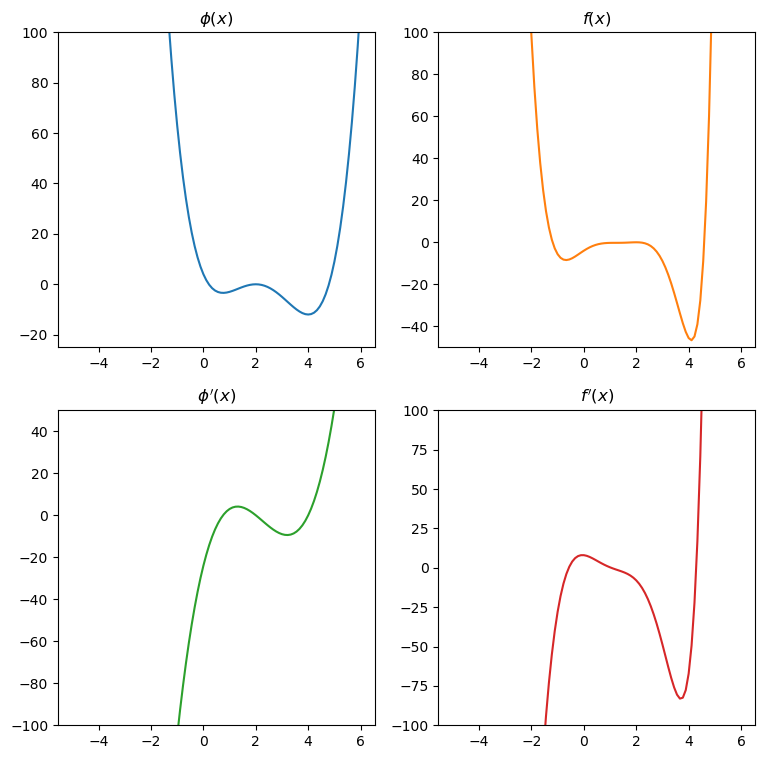

In [4]:
#plotting functions to estimate extrema
x = np.linspace (-5,6,100)
fig, axs = plt.subplots(2, 2, figsize = (9,9))
axs[0, 0].plot(x, phi(x))
axs[0 ,0].set_ylim(-25,100)
axs[0, 0].set_title(r'$\phi(x)$')
axs[0, 1].plot(x, f(x), 'tab:orange')
axs[0, 1].set_title(r'$f(x)$')
axs[0 ,1].set_ylim(-50,100)
axs[1, 0].plot(x, phi_prime(x), 'tab:green')
axs[1, 0].set_title(r"$\phi'(x)$")
axs[1, 0].set_ylim(-100,50)
axs[1, 1].plot(x, f_prime(x), 'tab:red')
axs[1, 1].set_title(r"$f'(x)$")
axs[1 ,1].set_ylim(-100,100)
fig.show()

In [5]:
#finding local minima
#initial guesses
phi_intervals =[[0.5,1.5],[3.5,4.5]]
phi_prime_intervals=[[3,4]]
f_intervals = [[3,4.5], [-3,1]]
f_prime_intervals = [[3,4],[0,1]]

#evaluating golden_section 
phi_min = [golden_section(phi, a, b) for a,b in phi_intervals] 
phi_prime_min = [golden_section(phi_prime, a, b) for a,b in phi_prime_intervals]
f_min = [golden_section(f,a,b) for a,b in f_intervals]
f_prime_min = [golden_section(f_prime,a,b) for a,b in f_prime_intervals]

#corresponding y_values
y_phi_min = [phi(x) for x in phi_min] 
y_phi_prime_min = [phi_prime(x) for x in phi_prime_min]
y_f_min = [f(x) for x in f_min]
y_f_prime_min = [f_prime(x) for x in f_prime_min]

print('phi minima/s:', phi_min)
print('phi_prime minima/s', phi_prime_min)
print('f minima/s', f_min)
print('f_prime_minima/s', f_prime_min)

phi minima/s: [0.749999981905141, 4.00000001144115]
phi_prime minima/s [3.1964847212929577]
f minima/s [4.103324884656219, -0.679862013120544]
f_prime_minima/s [3.7054717531355084, 0.9999999964644903]


In [6]:
#finding local maxima
#initial guesses
phi_intervals2=[[0,4]]
phi_prime_intervals2 = [[-1,3]]
f_intervals2 = [[-1,3], [0,1]]
f_prime_intervals2 = [[-2,2]]

#evaluating flipped golden_section
phi_max = [golden_section(lambda x: -phi(x),a,b) for a,b in phi_intervals2]
phi_prime_max = [golden_section(lambda x: -phi_prime(x),a,b) for a,b in phi_prime_intervals2]
f_max = [golden_section(lambda x: -f(x), a,b) for a,b in f_intervals2]
f_prime_max = [golden_section(lambda x: -f_prime(x),a,b) for a,b in f_prime_intervals2]

#corresponding y_values
y_phi_max = [phi(x) for x in phi_max] 
y_phi_prime_max = [phi_prime(x) for x in phi_prime_max]
y_f_max = [f(x) for x in f_max]
y_f_prime_max = [f_prime(x) for x in f_prime_max]

print('phi maxima:', phi_max)
print('phi_prime maxima: ', phi_prime_max)
print('f maxima: ', f_max)
print('f_prime_maxima: ', f_prime_max)

phi maxima: [1.9999999783928877]
phi_prime maxima:  [1.3035152574939837]
f maxima:  [2.000000057449288, 0.9999999964644903]
f_prime_maxima:  [-0.054532864234239614]


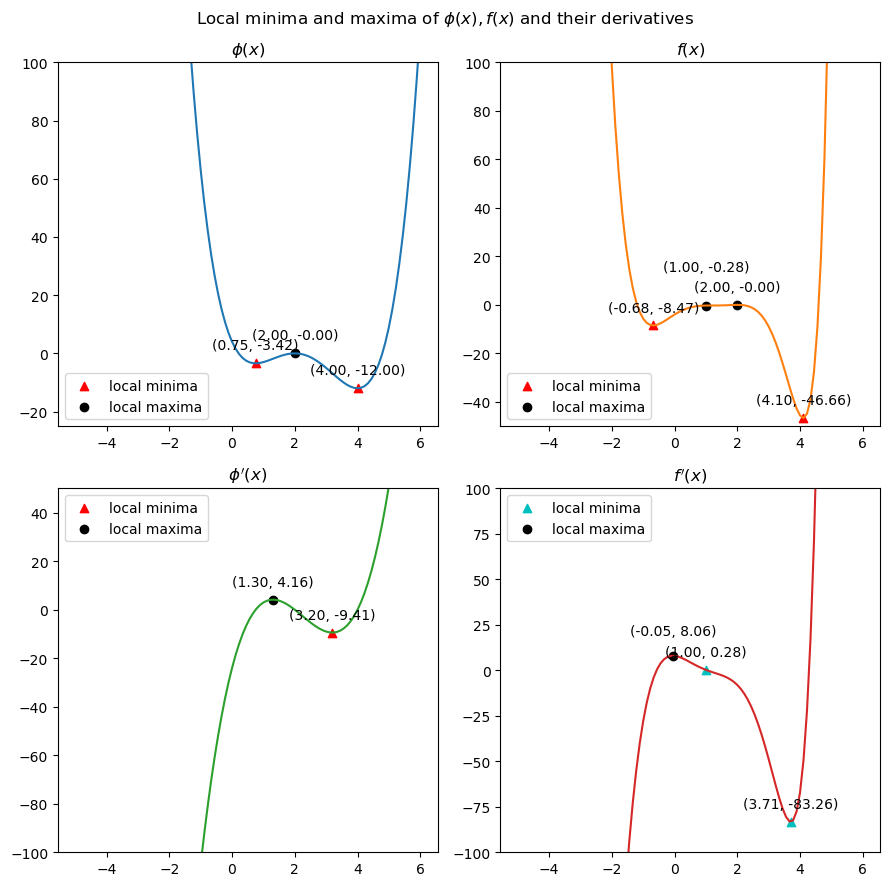

In [7]:
fig, axs = plt.subplots(2, 2, figsize = (9,9))
axs[0, 0].plot(x, phi(x))
axs[0 ,0].set_ylim(-25,100)
axs[0, 0].scatter(phi_min,y_phi_min, marker = '^', color='r',label = 'local minima') #marks local minima
axs[0, 0].scatter(phi_max,y_phi_max, marker= 'o', color = 'k', label = 'local maxima') #marks local maxima
for i,k in zip(phi_min, y_phi_min): #annotates coordinates for minima
    axs[0, 0].annotate(f"({i:.2f}, {k:.2f})", (i, k), textcoords="offset points", xytext=(0, 10), ha='center')
for i,k in zip(phi_max, y_phi_max): #annotates coordinates for maxima 
    axs[0, 0].annotate(f"({i:.2f}, {k:.2f})", (i, k), textcoords="offset points", xytext=(0, 10), ha='center')
axs[0, 0].set_title(r'$\phi(x)$')
axs[0, 0].legend()

axs[0 ,1].set_ylim(-50,100)
axs[0, 1].plot(x, f(x), 'tab:orange')
axs[0, 1].scatter(f_min,y_f_min, marker='^', color = 'r', label='local minima')
axs[0, 1].scatter(f_max, y_f_max, marker='o', color = 'k', label = 'local maxima')
axs[0, 1].set_title(r'$f(x)$')
axs[0, 1].legend()
for i,k in zip(f_min, y_f_min): 
    axs[0, 1].annotate(f"({i:.2f}, {k:.2f})", (i, k), textcoords="offset points", xytext=(0, 10), ha='center')
for index,(i,k) in enumerate(zip(f_max, y_f_max)): 
    offset = 10 if index == 0 else 25
    axs[0, 1].annotate(f"({i:.2f}, {k:.2f})", (i, k), textcoords="offset points", xytext=(0, offset), ha='center')
    
axs[1, 0].plot(x, phi_prime(x), 'tab:green')
axs[1, 0].scatter(phi_prime_min,y_phi_prime_min, marker='^', color = 'r', label='local minima')
axs[1, 0].scatter(phi_prime_max,y_phi_prime_max, marker='o', color ='k', label='local maxima')
axs[1, 0].set_ylim(-100,50)
axs[1, 0].set_title(r"$\phi'(x)$")
axs[1, 0].legend()
for i, k in zip(phi_prime_min, y_phi_prime_min): 
    axs[1, 0].annotate(f"({i:.2f}, {k:.2f})", (i, k), textcoords="offset points", xytext=(0, 10), ha='center')
for i, k in zip(phi_prime_max, y_phi_prime_max): 
    axs[1, 0].annotate(f"({i:.2f}, {k:.2f})", (i, k), textcoords="offset points", xytext=(0, 10), ha='center')

axs[1, 1].plot(x, f_prime(x), 'tab:red')
axs[1, 1].scatter(f_prime_min, y_f_prime_min, marker='^', color='c', label='local minima')
axs[1, 1].scatter(f_prime_max, y_f_prime_max, marker='o', color='k', label='local maxima')
axs[1, 1].set_title(r"$f'(x)$")
axs[1 ,1].set_ylim(-100,100)
axs[1, 1].legend()
for i,k in zip(f_prime_min, y_f_prime_min): 
    axs[1, 1].annotate(f"({i:.2f}, {k:.2f})", (i, k), textcoords="offset points", xytext=(0, 10), ha='center')
for i,k in zip(f_prime_max, y_f_prime_max): 
    axs[1, 1].annotate(f"({i:.2f}, {k:.2f})", (i, k), textcoords="offset points", xytext=(0, 15), ha='center')
    
fig.suptitle(r'Local minima and maxima of $\phi(x), f(x)$ and their derivatives')
plt.tight_layout()
fig.show()

#### Problem 1 code summary
The script finds the local minima by using the golden section method function in Gezerlis while the maxima were located by evaluating golden_section on the negative of the function. The brackets/initial guesses were estimated from the initial plot of the functions. The functions were then plotted and the minima and maxima were marked and annotated. 

---

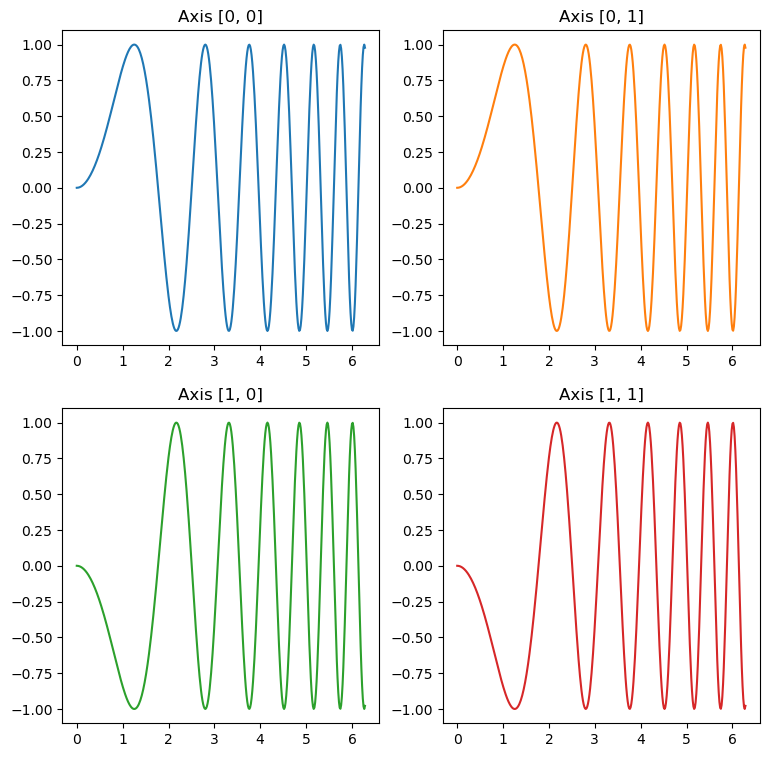

In [8]:
#sample incomplete 2 by 2 plot 

x = np.linspace(0, 2 * np.pi, 400)
y = np.sin(x ** 2)

fig, axs = plt.subplots(2, 2, figsize = (9,9))
axs[0, 0].plot(x, y)
axs[0, 0].set_title('Axis [0, 0]')
axs[0, 1].plot(x, y, 'tab:orange')
axs[0, 1].set_title('Axis [0, 1]')
axs[1, 0].plot(x, -y, 'tab:green')
axs[1, 0].set_title('Axis [1, 0]')
axs[1, 1].plot(x, -y, 'tab:red')
axs[1, 1].set_title('Axis [1, 1]')
fig.show()